In [3]:
# function to read the object ids from the parquet files 
import pandas as pd
from pathlib import Path


base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids")
parquet_files = [base_path / "extragalactic_lt20mag_candidate.parquet", 
                base_path / "sn_near_galaxy_candidate.parquet",
                base_path / "extragalactic_new_candidate.parquet"]

for i in parquet_files:
    df = (pd.read_parquet(i))
    print (df)
    df = df["diaObjectId"].values.tolist()
    list_of_object_Ids = ["170261592629837872", "170235219334922248"]
    for j in list_of_object_Ids:
        if j in df:
            print (f"{j} has passed this filter {i} and been stored in {df}")

        else: 
            print(f"The object Ids in this Parquet file are {df} \nand the specific object ID didn't pass the filter.")

          diaObjectId
0  170235219334922248
1  170261592629837872
2  314003014107006318
170261592629837872 has passed this filter C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids\extragalactic_lt20mag_candidate.parquet and been stored in ['170235219334922248', '170261592629837872', '314003014107006318']
170235219334922248 has passed this filter C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids\extragalactic_lt20mag_candidate.parquet and been stored in ['170235219334922248', '170261592629837872', '314003014107006318']
          diaObjectId
0  170028526511063098
1  170028526517354568
2  170028526533608163
3  170028526535180328
4  170028526800994812
5  170028534042984523
6  313998569462300707
7  313998569623257167
8  314003013678137685
9  314003014420004875
The object Ids in this Parquet file are ['170028526511063098', '170028526517354568', '170028526533608163', '170028526535180328', '170028526800994812', '17

In [6]:
# function to read classifications score from the classified parquet files. 
import pandas as pd
from pathlib import Path

base_classified_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_classified")
classified_parquet_files = [base_classified_path / "extragalactic_lt20mag_candidates_classified.parquet",
                            base_classified_path / "extragalactic_new_candidate_classified.parquet",
                            base_classified_path / "sn_near_galaxy_candidate_classified.parquet"]

for cl_parquet_files in classified_parquet_files:
    df = pd.read_parquet(cl_parquet_files)
    print (df)

        r:diaObjectId  clf_cats_class_mode  clf_cats_score_max  \
0  170235219334922248                   11            0.999141   
1  170261592629837872                   11            0.999990   
2  314003014107006318                   12            0.999858   

   clf_cats_score_mean  clf_earlySNIa_max  clf_earlySNIa_mean  clf_snn_max  \
0             0.956701           0.642004           -0.181339     0.916448   
1             0.877774           0.816234            0.031208     0.934886   
2             0.900465          -1.000000           -1.000000     0.928303   

   clf_snn_mean  n_detections  
0      0.853843            39  
1      0.852941            36  
2      0.814623            67  
        r:diaObjectId  clf_cats_class_mode  clf_cats_score_max  \
0  170301167209807939                   -1            0.000000   
1  170301167243886614                   -1            0.000000   
2  170301167279538215                   -1            0.000000   
3  170301167288975422         

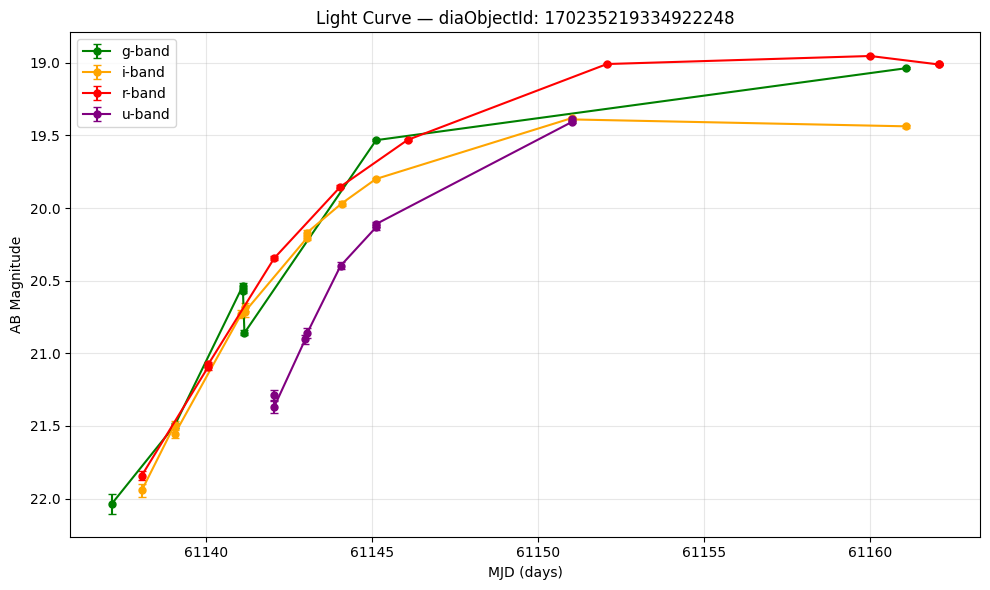

<Figure size 640x480 with 0 Axes>

In [ ]:
# fast plotter of the light curves for the object IDs
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OBJECT_ID = "170235219334922248"

def fetch_lightcurve(diaObjectId: str) -> pd.DataFrame:
    r = requests.post(
        "https://api.lsst.fink-portal.org/api/v1/sources",
        json={
            "diaObjectId": diaObjectId,
            "columns": "r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr,r:band",
            "output-format": "json",
        },
    )
    r.raise_for_status()
    return pd.read_json(io.BytesIO(r.content))

def flux_to_mag(flux, flux_err):
    """Convert nanojansky flux to AB magnitude with propagated uncertainty."""
    mag = -2.5 * np.log10(flux) + 31.4
    mag_err = (2.5 / np.log(10)) * (flux_err / flux)
    return mag, mag_err

def plot_lightcurve(df: pd.DataFrame, diaObjectId: str):
    # Filter out negative flux (non-detections)
    df = df[df["r:psfFlux"] > 0].copy()

    df["mag"], df["mag_err"] = flux_to_mag(df["r:psfFlux"], df["r:psfFluxErr"])

    band_colours = {"u": "purple", "g": "green", "r": "red", "i": "orange", "z": "black", "y": "brown"}

    fig, ax = plt.subplots(figsize=(10, 6))

    for band, group in df.groupby("r:band"):
        colour = band_colours.get(band, "black")
        ax.errorbar(
            group["r:midpointMjdTai"],
            group["mag"],
            yerr=group["mag_err"],
            fmt="o-",
            color=colour,
            label=f"{band}-band",
            capsize=3,
            markersize=5,
        )

    ax.invert_yaxis()  # Magnitudes are inverted — brighter = smaller number
    ax.set_xlabel("MJD (days)")
    ax.set_ylabel("AB Magnitude")
    ax.set_title(f"Light Curve — diaObjectId: {diaObjectId}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.savefig('170235219334922248_light_curve.png')

df = fetch_lightcurve(OBJECT_ID)
plot_lightcurve(df, OBJECT_ID)

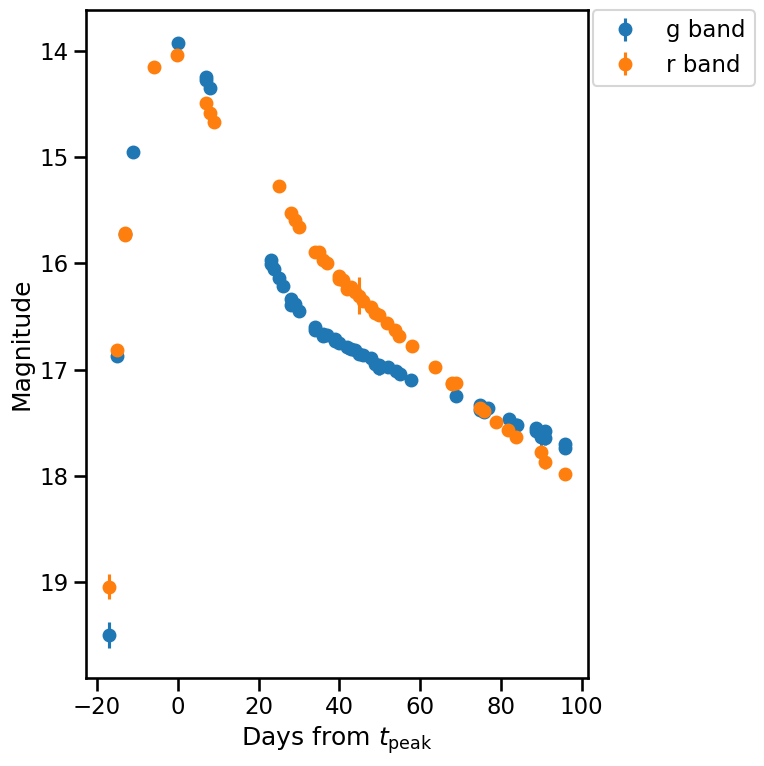

In [9]:
# ZTF good SNe Ia plotter for example plot of what a good supernova light curve looks like.

import io
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context("talk")

r = requests.post(
    "https://api.ztf.fink-portal.org/api/v1/objects",
    json={"objectId": "ZTF26aabbzvl", "withupperlim": "True"},
)

pdf = pd.read_json(io.BytesIO(r.content))

colordic = {1: "C0", 2: "C1"}
namedic = {1: "g", 2: "r"}

# Find t_peak: MJD of the brightest (lowest magpsf) valid detection across g and r
mask_valid = pdf["d:tag"] == "valid"
t_peak = pdf[mask_valid].loc[pdf[mask_valid]["i:magpsf"].idxmin(), "i:jd"] - 2400000.5

fig, ax = plt.subplots(figsize=(8, 8))

for filt in [1, 2]:
    mask_filt = pdf["i:fid"] == filt

    det = pdf[mask_valid & mask_filt]
    ax.errorbar(
        det["i:jd"].apply(lambda x: x - 2400000.5) - t_peak,
        det["i:magpsf"],
        det["i:sigmapsf"],
        ls="",
        marker="o",
        color=colordic[filt],
        label=f"{namedic[filt]} band",
    )

ax.invert_yaxis()
ax.set_xlabel(r"Days from $t_{\mathrm{peak}}$")
ax.set_ylabel("Magnitude")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", borderaxespad=0)
fig.tight_layout()
plt.show()